# v34 run平均ランカー — 「seed32を尤度でまとめた後の出力」27本のランキング(ユーザー案)
per-seed 576本(oracle 4.15, d_meta回収15%)に対し、**run平均 = 安定した少数候補**を直接ランキングする。

候補(**PF再実行ゼロ**):
- pfダンプ由来: pf_1/2/3 × tw/self/nbr × sm/fw = 18本(seed_dump_pf{1,2,3}.npz)
- **v28_4 parquet 由来: r系バンク(r0/r1/r4_seed32)× tw/self/nbr × sm = 9本**
  (pf_ancc_k/pf_self_k/pf_nbr_k 列そのもの。fwは列に無いためsmのみ)
- r系のGR残差チャネル用 grid は create の入力構築(CPU・数分)で再計算し `rgrid_cache.npz` にキャッシュ。

プロトコルは lab と同一: 固定fold / q̂井戸内z → softmax β{0.25,0.5,1,2} + top-n{1,2,4,8}(top-1=hard選択) /
結果は ranker_lab_results.json に `f_runmean` として蓄積。
※候補構成を変えたら lab_q_f_runmean_f*.npy を削除してから再実行。
比較: 自前cons(候補median)・oracle(1本)。参考 = d_meta 7.5597 / cons576 8.1744 / oracle576 4.147。


In [1]:
# ===== ロード(pfダンプ + v28_4 parquet r系列 + grid再構築) =====
import json, warnings, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
warnings.filterwarnings("ignore")
matplotlib.rcParams["font.family"] = "Meiryo"; matplotlib.rcParams["axes.unicode_minus"] = False

PROJECT = Path(r"C:\Users\kosaka256\Documents\rogii_claude")
V28_ART = PROJECT / "v28" / "artifacts_v28"
V284_PQ = PROJECT / "v28" / "artifacts_v28_4" / "data" / "train.parquet"
V32_ART = PROJECT / "v32" / "artifacts_v32"
ART = PROJECT / "v34" / "artifacts_v34"

tbl = pq.read_table(V28_ART / "data" / "train.parquet",
                    columns=["well", "target", "last_known_tvt", "pf_nbr_has"])
g = tbl.column("well").to_pandas().to_numpy()
lk = tbl.column("last_known_tvt").to_numpy(zero_copy_only=False).astype(np.float64)
tvt_true = lk + tbl.column("target").to_numpy(zero_copy_only=False).astype(np.float64)
has = tbl.column("pf_nbr_has").to_numpy(zero_copy_only=False).astype(np.float64)
wid = list(pd.unique(g)); rows_of = {w: np.where(g == w)[0] for w in wid}
HARD = set(pd.read_csv(V32_ART / "hardcore_diag.csv", index_col=0).query(
    "rmse_prior >= 10 and abs(bias) > 8").index) & set(wid)
def rmse(e):
    e = e[np.isfinite(e)]
    return float(np.sqrt(np.mean(e ** 2))) if e.size else np.nan
FOLD = {k: int(v) for k, v in json.loads((ART / "ranker_folds.json").read_text()).items()}

# ---- pfダンプ(sm/fw per-seed → run平均を作る) ----
PF_BANKS = ["pf1", "pf2", "pf3"]
DUMPS = {b: np.load(ART / f"seed_dump_pf{b[-1]}.npz") for b in PF_BANKS}
KEYS = {b: set(DUMPS[b].files) for b in PF_BANKS}
SRCS = ("tw", "self", "nbr"); FLTS = (("sm", "ps"), ("fw", "pfw"))

# ---- v28_4 parquet(r系バンクの sm run平均列)----
R_BANKS = ["rp1", "rp2", "rp3"]           # = create の PF_BANK(r0/r1/r4_seed32)の suffix 1/2/3
R_LABELS = {"rp1": "r0_seed32", "rp2": "r1_seed32", "rp3": "r4_seed32"}
RCOL = {("rp1", "tw"): "pf_ancc_1", ("rp2", "tw"): "pf_ancc_2", ("rp3", "tw"): "pf_ancc_3",
        ("rp1", "self"): "pf_self_1", ("rp2", "self"): "pf_self_2", ("rp3", "self"): "pf_self_3",
        ("rp1", "nbr"): "pf_nbr_1", ("rp2", "nbr"): "pf_nbr_2", ("rp3", "nbr"): "pf_nbr_3"}
RSTD = {"rp1": "pf_ancc_std_1", "rp2": "pf_ancc_std_2", "rp3": "pf_ancc_std_3"}
t4 = pq.read_table(V284_PQ, columns=["well"] + sorted(set(RCOL.values()) | set(RSTD.values())))
g4 = t4.column("well").to_pandas().to_numpy()
assert len(g4) == len(g) and (g4 == g).all(), "v28_4 parquet の行整列が本家と不一致"
C4 = {c: t4.column(c).to_numpy(zero_copy_only=False).astype(np.float64)
      for c in t4.schema.names if c != "well"}
del t4
BANKS = PF_BANKS + R_BANKS
print(f"wells {len(wid)} | banks {BANKS} | 最大候補 {len(PF_BANKS)*6 + len(R_BANKS)*3}本/井戸")


wells 773 | banks ['pf1', 'pf2', 'pf3', 'rp1', 'rp2', 'rp3'] | 最大候補 27本/井戸


In [2]:
# ===== r系バンクの grid 再構築(PFの入力なので実行不要・CPU数分・キャッシュ付き) =====
import sys
sys.path.insert(0, str(PROJECT / "v28"))
import create_train_parquet_v28 as CR

RG_FP = ART / "rgrid_cache.npz"
if RG_FP.exists():
    _rg = np.load(RG_FP)
    RGRID = {}
    for key in _rg.files:
        w, b, kind = key.split("|")
        RGRID.setdefault((w, b), {})[kind] = _rg[key]
    print(f"rgrid_cache 読み込み: {len(RGRID)} (well,bank)")
else:
    BASE = CR.DATA_DIR_V26 / "train"
    print("[nbr] 近傍探索 ...")
    NREFS, NBH = {}, {}
    for w in wid:
        hw = pd.read_csv(BASE / f"{w}__horizontal_well.csv", usecols=["X", "Y"])
        cx, cy = float(hw["X"].mean()), float(hw["Y"].mean())
        refw = CR.neighbors_of(cx, cy, exclude_wid=w)
        use = len(refw) >= CR.NEED_REFS
        NREFS[w] = [CR._ref_grtvt(r) for r, _ in refw] if use else []
        NBH[w] = int(use)
    RGRID = {}; t0 = time.time()
    for bi, b in enumerate(R_BANKS):
        Pk = {**CR.PF_LIB[R_LABELS[b]], "smooth_lag": CR.SMOOTH_LAG}
        for wi, w in enumerate(wid):
            hw = pd.read_csv(BASE / f"{w}__horizontal_well.csv")
            tw = pd.read_csv(BASE / f"{w}__typewell.csv").sort_values("TVT")
            twt = tw["TVT"].to_numpy(float); twg = tw["GR"].to_numpy(float)
            bs = CR.build_smoother_inputs(hw, twt, twg, Pk)
            if bs is None: continue
            sf = CR.build_inputs_self(hw, twt, twg, Pk)
            nb = CR.build_inputs_nbr(hw, twt, twg, Pk, NREFS[w]) if NBH[w] else None
            d = dict(gg_tw=bs["gg"].astype(np.float32), gg_self=sf["gg"].astype(np.float32),
                     meta=np.array([bs["gmin"], bs["gst"], bs["gs"]], np.float64),
                     gr=bs["gr"].astype(np.float32), md=bs["md"].astype(np.float32),
                     z=bs["z"].astype(np.float32), ir=np.array([bs["ir"]], np.float64))
            if nb is not None: d["gg_nbr"] = nb["gg"].astype(np.float32)
            RGRID[(w, b)] = d
            if (wi + 1) % 200 == 0:
                print(f"  {b}: {wi+1}/{len(wid)}({time.time()-t0:.0f}s)")
    pack = {}
    for (w, b), d in RGRID.items():
        for kind, arr in d.items():
            pack[f"{w}|{b}|{kind}"] = arr
    np.savez(RG_FP, **pack)
    print(f"rgrid_cache 保存: {RG_FP}")


PF parameter sets:
  pf_1: suffix=_1, N=600, seeds=32, jump=(0.002, 5.0)
  pf_2: suffix=_2, N=600, seeds=32, jump=(0.0, 10.0)
  pf_3: suffix=_3, N=600, seeds=32, jump=(0.002, 5.0)
[nbr] 近傍探索 ...
  rp1: 200/773(3s)
  rp1: 400/773(6s)
  rp1: 600/773(9s)
  rp2: 200/773(14s)
  rp2: 400/773(17s)
  rp2: 600/773(20s)
  rp3: 200/773(25s)
  rp3: 400/773(28s)
  rp3: 600/773(31s)
rgrid_cache 保存: C:\Users\kosaka256\Documents\rogii_claude\v34\artifacts_v34\rgrid_cache.npz


In [3]:
# ===== run平均候補の構築(pfダンプ18本 + parquet r系9本) =====
t0 = time.time(); RM = {}
for w in wid:
    r = rows_of[w]
    nbr_ok = np.nanmean(has[r]) > 0.5
    trs, meta = [], []
    Tmin = len(r)
    for b in PF_BANKS:                     # dump: sm/fw の run平均を ww で構成
        z = DUMPS[b]
        for src in SRCS:
            if src == "nbr" and not nbr_ok: continue
            if f"{w}|ps_{src}" not in KEYS[b]: continue
            ww_ = z[f"{w}|ww_{src}"]
            for flt, pref in FLTS:
                ps = z[f"{w}|{pref}_{src}"]
                Tmin = min(Tmin, ps.shape[1])
                tr_ = (ww_[:, None] * ps.astype(np.float64)).sum(0)
                dse = float(np.nanstd(np.nanmedian(ps.astype(np.float64) - tr_[None, :ps.shape[1]], axis=1)))
                went = float(-(ww_ * np.log(np.maximum(ww_, 1e-12))).sum())
                trs.append(tr_); meta.append((b, src, flt, dse, went, float(ww_.max())))
    for b in R_BANKS:                      # parquet: sm run平均の列そのもの
        if (w, b) not in RGRID: continue
        dse = float(np.nanmedian(C4[RSTD[b]][r]))
        for src in SRCS:
            if src == "nbr" and not nbr_ok: continue
            v = C4[RCOL[(b, src)]][r]
            if np.isfinite(v).sum() < max(10, 0.3 * len(r)): continue
            trs.append(v.copy()); meta.append((b, src, "sm", dse, 0.0, 0.0))
    if len(trs) < 4 or Tmin < 5: continue
    TR = np.stack([t_[:Tmin] for t_ in trs], 0)
    err = np.nanmedian(np.abs(TR - tvt_true[r[:Tmin]][None, :]), axis=1)
    ok = np.isfinite(err)
    if ok.sum() < 4: continue
    TR = TR[ok]; err = err[ok]; meta = [m for m, o in zip(meta, ok) if o]
    RM[w] = dict(TR=np.nan_to_num(TR, nan=np.nan).astype(np.float32), T=Tmin,
                 err=err.astype(np.float32), meta=meta,
                 cons=np.nanmedian(TR, axis=0).astype(np.float32),
                 p10=np.nanpercentile(TR, 10, axis=0).astype(np.float32),
                 p90=np.nanpercentile(TR, 90, axis=0).astype(np.float32))
cons_ov = rmse(np.concatenate([RM[w]["cons"] - tvt_true[rows_of[w][:RM[w]["T"]]] for w in RM]))
or1_ov = rmse(np.concatenate([RM[w]["TR"][int(np.argmin(RM[w]["err"]))] - tvt_true[rows_of[w][:RM[w]["T"]]] for w in RM]))
navg = np.mean([len(RM[w]["TR"]) for w in RM])
print(f"RM {len(RM)}井戸 / 平均候補 {navg:.1f}本 ({time.time()-t0:.0f}s)")
print(f"基準: cons(run平均median) {cons_ov:.4f} / ★oracle(1本) {or1_ov:.4f}")
print(f"参考: per-seed cons576 8.1744 / oracle576 4.147 / d_meta 7.5597")


RM 773井戸 / 平均候補 24.8本 (190s)
基準: cons(run平均median) 7.1055 / ★oracle(1本) 4.8783
参考: per-seed cons576 8.1744 / oracle576 4.147 / d_meta 7.5597


In [4]:
# ===== TCNスコアラ学習(labと同一プロトコル・foldチェックポイント付き) =====
import torch, torch.nn as nn, torch.nn.functional as F
DEV = "cuda" if torch.cuda.is_available() else "cpu"
STRIDE, TAU, EPOCHS, LR = 4, 0.5, 20, 3e-4
torch.manual_seed(0)
B_ID = {b: i for i, b in enumerate(BANKS)}
S_ID = {"tw": 0, "self": 1, "nbr": 2}
META_DIM = len(BANKS) + 3 + 1 + 3   # bank onehot + src onehot + flt_sm + (seed_disp, went, wmax)

def _grids_of(w, b):
    if b in PF_BANKS:
        z = DUMPS[b]
        out = dict(meta=z[f"{w}|meta"], gr=z[f"{w}|gr"], md=z[f"{w}|md"], zz=z[f"{w}|z"],
                   ir=float(z[f"{w}|ir"]), gg_tw=z[f"{w}|gg_tw"], gg_self=z[f"{w}|gg_self"])
        if f"{w}|gg_nbr" in KEYS[b]: out["gg_nbr"] = z[f"{w}|gg_nbr"]
        return out
    d = RGRID.get((w, b))
    if d is None: return None
    out = dict(meta=d["meta"], gr=d["gr"], md=d["md"], zz=d["z"], ir=float(d["ir"][0]),
               gg_tw=d["gg_tw"], gg_self=d["gg_self"])
    if "gg_nbr" in d: out["gg_nbr"] = d["gg_nbr"]
    return out

def build_ch(w):
    d = RM[w]; T = d["T"]
    TR = d["TR"][:, ::STRIDE].astype(np.float32)
    cons = d["cons"][::STRIDE]; p10 = d["p10"][::STRIDE]; p90 = d["p90"][::STRIDE]
    n = len(TR)
    g0 = _grids_of(w, "pf1")
    md_ = g0["md"].astype(np.float32)[:T][::STRIDE]; zz = g0["zz"].astype(np.float32)[:T][::STRIDE]
    ir0 = g0["ir"]
    off = np.clip((TR - cons[None, :]) / 10.0, -6, 6)
    env = np.clip((TR - p10[None, :]) / (p90 - p10 + 1e-3)[None, :] - 0.5, -3, 3)
    dmd = np.maximum(np.diff(md_), 1.0)
    dip = np.zeros_like(TR)
    dip[:, 1:] = np.clip(np.nan_to_num((np.diff(TR + zz[None, :], axis=1) / dmd[None, :] - ir0) * 100.0), -4, 4)
    RES = {k: np.zeros_like(TR) for k in ("tw", "self", "nbr")}
    for i, (b, src, flt, dse, went, wmax) in enumerate(d["meta"]):
        gb = _grids_of(w, b)
        if gb is None: continue
        gmin, gst, gs = gb["meta"]; gr = gb["gr"].astype(np.float32)[:T][::STRIDE]
        for nmk in ("tw", "self", "nbr"):
            gg = gb.get(f"gg_{nmk}")
            if gg is None: continue
            gg = gg.astype(np.float32); G = len(gg)
            ii = np.clip(np.nan_to_num((TR[i] - gmin) / gst), 0.0, G - 1.000001)
            i0 = ii.astype(int); t = ii - i0
            eg = gg[i0] * (1 - t) + gg[np.minimum(i0 + 1, G - 1)] * t
            RES[nmk][i] = np.clip(np.nan_to_num((gr - eg) / max(float(gs), 1e-3)), -4, 4)
    grz = g0["gr"].astype(np.float32)[:T][::STRIDE]
    grz = np.clip((grz - np.nanmedian(grz)) / (np.nanstd(grz) + 1e-3), -4, 4)
    grz = np.nan_to_num(np.broadcast_to(grz, (n, len(grz))))
    X = np.stack([np.nan_to_num(off), np.nan_to_num(env), RES["tw"], RES["self"], RES["nbr"], dip, grz], 1)
    M = np.zeros((n, META_DIM), np.float32)
    for i, (b, src, flt, dse, went, wmax) in enumerate(d["meta"]):
        M[i, B_ID[b]] = 1; M[i, len(BANKS) + S_ID[src]] = 1
        M[i, len(BANKS) + 3] = float(flt == "sm")
        M[i, len(BANKS) + 4] = min(dse, 25.0) / 5.0
        M[i, len(BANKS) + 5] = went / 3.5; M[i, len(BANKS) + 6] = wmax
    return np.ascontiguousarray(X).astype(np.float16), M

class ChanLN(nn.Module):
    def __init__(self, c):
        super().__init__(); self.ln = nn.LayerNorm(c)
    def forward(self, x): return self.ln(x.transpose(1, 2)).transpose(1, 2)
class Scorer(nn.Module):
    def __init__(self, cin=7, ch=32, dmeta=META_DIM):
        super().__init__()
        self.inp = nn.Conv1d(cin, ch, 1)
        self.blocks = nn.ModuleList()
        for dil in (1, 2, 4, 8):
            self.blocks.append(nn.ModuleList([
                nn.Conv1d(ch, ch, 5, padding=2 * dil, dilation=dil), ChanLN(ch), nn.Conv1d(ch, ch, 1)]))
        self.emb = nn.Linear(2 * ch, 64)
        self.mp = nn.Sequential(nn.Linear(dmeta, 64), nn.GELU(), nn.Linear(64, 64))
        self.head = nn.Sequential(nn.Linear(64, 64), nn.GELU(), nn.Linear(64, 1))
    def forward(self, x, meta):
        h = self.inp(x)
        for cv, ln, pw in self.blocks:
            h = h + pw(F.gelu(ln(cv(h))))
        e = self.emb(torch.cat([h.mean(-1), h.amax(-1)], -1)) + self.mp(meta)
        return self.head(e).squeeze(-1)

print("チャネル前計算(GPU常駐) ...", flush=True); t0 = time.time()
CH = {}; MB = {}; PSTAR = {}; EZ = {}
for w in RM:
    xw, mw = build_ch(w)
    CH[w] = torch.from_numpy(xw).to(DEV); MB[w] = torch.from_numpy(mw).to(DEV)
    e = RM[w]["err"].astype(np.float64)
    ez = (e - e.mean()) / (e.std() + 1e-9)
    EZ[w] = ez.astype(np.float32)
    PSTAR[w] = F.softmax(torch.from_numpy(-EZ[w] / TAU).to(DEV), 0)
print(f"  done {time.time()-t0:.0f}s")

def quick_eval(Qw, wells, beta=0.5):
    e_e, e_c = [], []
    for w in wells:
        q = Qw[w].astype(np.float64); q = (q - q.mean()) / (q.std() + 1e-9)
        wgt = np.exp(-beta * q); wgt = wgt / wgt.sum()
        d = RM[w]
        est = (wgt[:, None] * d["TR"].astype(np.float64)).sum(0)
        tr_ = tvt_true[rows_of[w][:d["T"]]]
        e_e.append(est - tr_); e_c.append(d["cons"].astype(np.float64) - tr_)
    return rmse(np.concatenate(e_e)), rmse(np.concatenate(e_c))

Qw = {}
wells_all = [w for w in RM]
for f in range(5):
    trw = [w for w in wells_all if FOLD.get(w) != f]; vaw = [w for w in wells_all if FOLD.get(w) == f]
    fp = ART / f"lab_q_f_runmean_f{f}.npy"
    if fp.exists():
        arr = np.load(fp); off = 0
        for w in vaw:
            n = len(RM[w]["TR"]); Qw[w] = arr[off:off + n]; off += n
        ee, cc = quick_eval(Qw, vaw)
        print(f"fold{f} [cache]: 集約(β0.5) {ee:.4f} vs cons {cc:.4f}", flush=True)
        continue
    mdl = Scorer().to(DEV)
    opt = torch.optim.AdamW(mdl.parameters(), lr=LR, weight_decay=1e-4)
    rng = np.random.default_rng(f)
    for ep in range(EPOCHS):
        mdl.train(); tot = 0.0
        for j in rng.permutation(len(trw)):
            w = trw[j]
            s = mdl(CH[w].float(), MB[w])
            loss = -(PSTAR[w] * F.log_softmax(s, 0)).sum()
            opt.zero_grad(); loss.backward(); opt.step(); tot += float(loss)
        if ep % 5 == 4:
            print(f"fold{f} ep{ep+1}: loss {tot/len(trw):.4f}", flush=True)
    mdl.eval()
    with torch.no_grad():
        for w in vaw:
            Qw[w] = -mdl(CH[w].float(), MB[w]).float().cpu().numpy()
    np.save(fp, np.concatenate([Qw[w] for w in vaw]))
    ee, cc = quick_eval(Qw, vaw)
    print(f"fold{f} done: 集約(β0.5) {ee:.4f} vs cons {cc:.4f}", flush=True)


チャネル前計算(GPU常駐) ...
  done 8s
fold0 ep5: loss 3.0303
fold0 ep10: loss 2.9531
fold0 ep15: loss 2.8723
fold0 ep20: loss 2.8097
fold0 done: 集約(β0.5) 6.7443 vs cons 7.0039
fold1 ep5: loss 3.0391
fold1 ep10: loss 2.9658
fold1 ep15: loss 2.8875
fold1 ep20: loss 2.8314
fold1 done: 集約(β0.5) 6.8129 vs cons 7.0128
fold2 ep5: loss 3.0385
fold2 ep10: loss 2.9597
fold2 ep15: loss 2.8789
fold2 ep20: loss 2.8223
fold2 done: 集約(β0.5) 6.0894 vs cons 6.3163
fold3 ep5: loss 3.0414
fold3 ep10: loss 2.9711
fold3 ep15: loss 2.8970
fold3 ep20: loss 2.8454
fold3 done: 集約(β0.5) 6.3940 vs cons 6.5465
fold4 ep5: loss 3.0264
fold4 ep10: loss 2.9493
fold4 ep15: loss 2.8746
fold4 ep20: loss 2.8226
fold4 done: 集約(β0.5) 8.2440 vs cons 8.4691


[f_runmean] softmax β0.25:7.0341 | softmax β0.5:6.8929 | softmax β1.0:6.7663 | softmax β2.0:6.7773 | top-1:7.3759 | top-2:7.0022 | top-4:6.7805 | top-8:6.9275
best softmax β1.0 = 6.7663(cons 7.1055 / oracle 4.8783 → 回収 15.2%)
勝率 487/773 | 硬い核Δ合計 -30.5 | fold別 ['6.406', '6.595', '6.076', '6.208', '8.323']


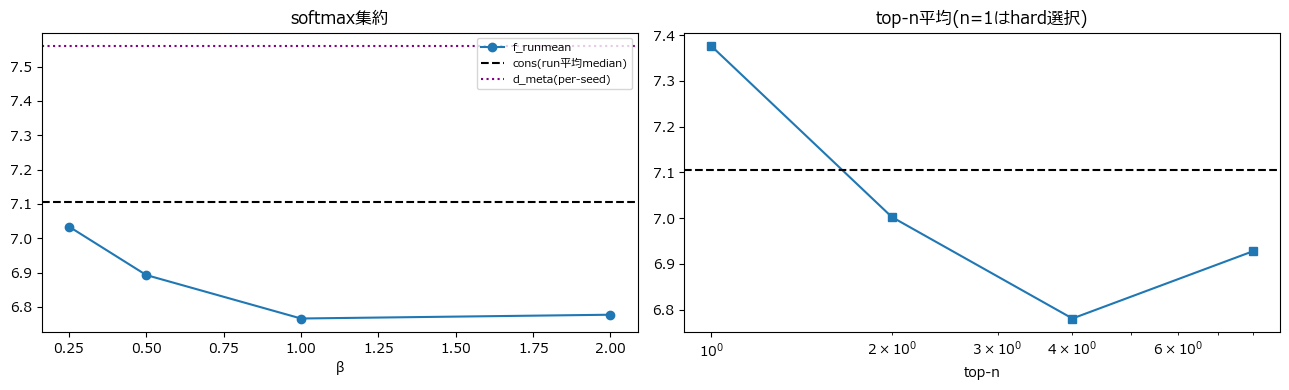

In [6]:
# ===== 固定プロトコル評価 → results蓄積 =====
QZ = {}
for w in RM:
    q = Qw[w].astype(np.float64); QZ[w] = (q - q.mean()) / (q.std() + 1e-9)
def agg_overall(mode, param, wells=None):
    e_all = []
    for w in (wells or RM):
        d = RM[w]; q = QZ[w]
        if mode == "softmax":
            wgt = np.exp(-param * q); wgt = wgt / wgt.sum()
        else:
            kk = min(param, len(q)); idx = np.argsort(q)[:kk]
            wgt = np.zeros(len(q)); wgt[idx] = 1.0 / kk
        est = (wgt[:, None] * d["TR"].astype(np.float64)).sum(0)
        e_all.append(est - tvt_true[rows_of[w][:d["T"]]])
    return rmse(np.concatenate(e_all))
res = [(f"softmax β{b}", "softmax", b) for b in (0.25, 0.5, 1.0, 2.0)] + \
      [(f"top-{n}", "topn", n) for n in (1, 2, 4, 8)]
scores = [(nm, agg_overall(mo, pa)) for nm, mo, pa in res]
best_nm, best_ov = min(scores, key=lambda x: x[1])
bmode, bparam = [(mo, pa) for nm, mo, pa in res if nm == best_nm][0]
rec = 100 * (cons_ov - best_ov) / max(cons_ov - or1_ov, 1e-9)
per_fold = [agg_overall(bmode, bparam, wells=[w for w in RM if FOLD.get(w) == f]) for f in range(5)]
win = 0; hard_gain = 0.0
for w in RM:
    d = RM[w]; q = QZ[w]
    if bmode == "softmax":
        wgt = np.exp(-bparam * q); wgt = wgt / wgt.sum()
    else:
        kk = min(bparam, len(q)); idx = np.argsort(q)[:kk]
        wgt = np.zeros(len(q)); wgt[idx] = 1.0 / kk
    est = (wgt[:, None] * d["TR"].astype(np.float64)).sum(0)
    tr_ = tvt_true[rows_of[w][:d["T"]]]
    en = rmse(est - tr_); ec = rmse(d["cons"].astype(np.float64) - tr_)
    if en < ec: win += 1
    if w in HARD: hard_gain += en - ec
print(f"[f_runmean] " + " | ".join(f"{nm}:{ov:.4f}" for nm, ov in scores))
print(f"best {best_nm} = {best_ov:.4f}(cons {cons_ov:.4f} / oracle {or1_ov:.4f} → 回収 {rec:.1f}%)")
print(f"勝率 {win}/{len(RM)} | 硬い核Δ合計 {hard_gain:+.1f} | fold別 {['%.3f' % v for v in per_fold]}")
RES_FP = ART / "ranker_lab_results.json"
allres = json.loads(RES_FP.read_text()) if RES_FP.exists() else {}
allres["f_runmean"] = dict(best_rule=best_nm, overall=best_ov, recovery_pct=rec, win=win,
                           n_wells=len(RM), hard_gain=hard_gain, fold_overall=per_fold,
                           cons=cons_ov, oracle1=or1_ov,
                           grid={nm: ov for nm, ov in scores}, banks=BANKS)
RES_FP.write_text(json.dumps(allres, indent=1))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
bs = [(pa, ov) for (nm, mo, pa), (_, ov) in zip(res, scores) if mo == "softmax"]
ax[0].plot([b for b, _ in bs], [o for _, o in bs], "o-", label="f_runmean")
ax[0].axhline(cons_ov, c="k", ls="--", label="cons(run平均median)")
ax[0].axhline(7.5597, c="purple", ls=":", label="d_meta(per-seed)")
ax[0].set_xlabel("β"); ax[0].legend(fontsize=8); ax[0].set_title("softmax集約")
ts = [(pa, ov) for (nm, mo, pa), (_, ov) in zip(res, scores) if mo == "topn"]
ax[1].plot([t for t, _ in ts], [o for _, o in ts], "s-")
ax[1].axhline(cons_ov, c="k", ls="--"); ax[1].set_xscale("log")
ax[1].set_xlabel("top-n"); ax[1].set_title("top-n平均(n=1はhard選択)")
plt.tight_layout(); plt.show()
